# Разведочный анализ данных (EDA) для проекта CyberGuard

Цель работы: изучить обучающий (`kdd_train.csv`) и тестовый (`kdd_test.csv`) наборы данных NSL-KDD, проверить качество данных, посмотреть статистику признаков и определить правила подготовки данных перед обучением моделей.

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Настраиваем отображение таблиц, чтобы столбцы не обрезались
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)

# Находим главную папку проекта, даже если ноутбук запущен из папки notebooks
current_dir = Path.cwd()
if current_dir.name == 'notebooks':
    project_root = current_dir.parent
else:
    project_root = current_dir

raw_dir = project_root / 'data' / 'raw'
processed_dir = project_root / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)

print('Папка проекта:', project_root)

Папка проекта: C:\Документы\Документы\python_projects\course_work


In [14]:
# Загружаем обучающую и тестовую выборки
df_train = pd.read_csv(raw_dir / 'kdd_train.csv')
df_test = pd.read_csv(raw_dir / 'kdd_test.csv')

print('Размер Train:', df_train.shape)
print('Размер Test: ', df_test.shape)

df_train.head()

Размер Train: (125973, 42)
Размер Test:  (22544, 42)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,labels
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal


In [15]:
# Проверяем, совпадают ли столбцы и их типы в обеих таблицах
same_columns = list(df_train.columns) == list(df_test.columns)
same_types = (df_train.dtypes == df_test.dtypes).all()

print('Столбцы полностью совпадают:', same_columns)
print('Типы данных совпадают:', same_types)
print()
print('Сколько столбцов каждого типа в Train:')
print(df_train.dtypes.value_counts())

Столбцы полностью совпадают: True
Типы данных совпадают: True

Сколько столбцов каждого типа в Train:
int64      23
float64    15
str         4
Name: count, dtype: int64


In [16]:
def check_missing_values(df, dataset_name):
    # Считаем обычные пустые значения NaN
    nan_count = int(df.isnull().sum().sum())

    # Проверяем текстовые столбцы на скрытые пропуски вроде пустых строк или '?'
    text_cols = df.select_dtypes(exclude='number').columns
    hidden_missing = {}

    for col in text_cols:
        values = df[col].dropna().astype(str).str.strip()
        bad_mask = (values == '') | (values == '?') | (values.str.lower().isin(['nan', 'null', 'none']))
        bad_count = int(bad_mask.sum())
        if bad_count > 0:
            hidden_missing[col] = bad_count

    print(f'{dataset_name}: пропусков NaN = {nan_count}, скрытых пропусков = {hidden_missing}')


check_missing_values(df_train, 'Train')
check_missing_values(df_test, 'Test')

Train: пропусков NaN = 0, скрытых пропусков = {}
Test: пропусков NaN = 0, скрытых пропусков = {}


In [17]:
feature_cols = [col for col in df_train.columns if col != 'labels']


def check_duplicates(df, dataset_name):
    full_dups = int(df.duplicated().sum())
    feature_dups = int(df.duplicated(subset=feature_cols).sum())

    # Проверяем, есть ли одинаковые по признакам строки, у которых одна помечена как normal, а другая как атака
    temp = df[feature_cols].copy()
    temp['binary_label'] = (df['labels'].astype(str).str.strip().str.lower() != 'normal').astype(int)

    only_dups = temp[temp.duplicated(subset=feature_cols, keep=False)]
    if len(only_dups) > 0:
        label_variants = only_dups.groupby(feature_cols)['binary_label'].nunique()
        conflicts = int((label_variants > 1).sum())
    else:
        conflicts = 0

    print(
        f'{dataset_name}: полных дубликатов = {full_dups}, '
        f'дубликатов по признакам = {feature_dups}, '
        f'конфликтов Normal/Attack = {conflicts}'
    )


check_duplicates(df_train, 'Train')
check_duplicates(df_test, 'Test')

# Проверяем, сколько записей из Test полностью совпадают по признакам с Train
train_unique_x = df_train[feature_cols].drop_duplicates()
matched_rows = df_test[feature_cols].merge(train_unique_x, on=feature_cols, how='inner')
print(f'Строк Test, совпадающих по признакам с Train: {len(matched_rows)} ({len(matched_rows) / len(df_test) * 100:.2f}%)')

Train: полных дубликатов = 0, дубликатов по признакам = 16, конфликтов Normal/Attack = 7
Test: полных дубликатов = 31, дубликатов по признакам = 35, конфликтов Normal/Attack = 3
Строк Test, совпадающих по признакам с Train: 15804 (70.10%)


In [18]:
# Ищем столбцы, в которых вообще не меняется значение (константы)
constant_train = [col for col in feature_cols if df_train[col].nunique() <= 1]
constant_test = [col for col in feature_cols if df_test[col].nunique() <= 1]

print('Константные столбцы в Train:', constant_train)
print('Константные столбцы в Test: ', constant_test)

# Сохраняем список полезных признаков без констант
active_features = [col for col in feature_cols if col not in constant_train]
print('Остаётся информативных признаков:', len(active_features))

Константные столбцы в Train: ['num_outbound_cmds']
Константные столбцы в Test:  ['num_outbound_cmds']
Остаётся информативных признаков: 40


In [19]:
# Делим признаки на числовые и категориальные (exclude='number' надёжно работает и в pandas 3.x)
numeric_cols = df_train[active_features].select_dtypes(include='number').columns.tolist()
categorical_cols = df_train[active_features].select_dtypes(exclude='number').columns.tolist()

print('Числовых признаков:', len(numeric_cols))
print('Категориальных признаков:', len(categorical_cols), categorical_cols)

Числовых признаков: 37
Категориальных признаков: 3 ['protocol_type', 'service', 'flag']


In [20]:
# Считаем основные статистики по числовым признакам обучающей выборки
df_num = df_train[numeric_cols]

numeric_stats = pd.DataFrame({
    'Минимум': df_num.min(),
    'Квантиль 0.1': df_num.quantile(0.1),
    'Квантиль 0.25': df_num.quantile(0.25),
    'Медиана': df_num.median(),
    'Среднее': df_num.mean(),
    'Квантиль 0.75': df_num.quantile(0.75),
    'Квантиль 0.9': df_num.quantile(0.9),
    'Максимум': df_num.max(),
    'Дисперсия': df_num.var(),
    'Уникальных': df_num.nunique(),
    'Асимметрия': df_num.skew()
})

numeric_stats.to_csv(processed_dir / 'numeric_stats.csv', encoding='utf-8-sig')

print('Признаки с самым сильным перекосом значений (выбросами):')
display(numeric_stats.sort_values('Асимметрия', ascending=False).head(10))
numeric_stats

Признаки с самым сильным перекосом значений (выбросами):


,Минимум,Квантиль 0.1,Квантиль 0.25,Медиана,Среднее,Квантиль 0.75,Квантиль 0.9,Максимум,Дисперсия,Уникальных,Асимметрия
is_host_login,0.0,0.0,0.0,0.0,0.000008,0.0,0.0,1.000000e+00,7.938209e-06,2,354.926753
dst_bytes,0.0,0.0,0.0,0.0,19779.114421,516.0,3375.8,1.309937e+09,1.617061e+13,9326,290.052911
num_compromised,0.0,0.0,0.0,0.0,0.279250,0.0,0.0,7.479000e+03,5.732214e+02,88,250.107883
num_root,0.0,0.0,0.0,0.0,0.302192,0.0,0.0,7.468000e+03,5.953414e+02,82,236.913724
src_bytes,0.0,0.0,0.0,44.0,45566.743000,276.0,848.0,1.379964e+09,3.446079e+13,3341,190.669347
urgent,0.0,0.0,0.0,0.0,0.000111,0.0,0.0,3.000000e+00,2.063827e-04,4,149.914509
land,0.0,0.0,0.0,0.0,0.000198,0.0,0.0,1.000000e+00,1.984174e-04,2,70.965063
num_shells,0.0,0.0,0.0,0.0,0.000413,0.0,0.0,2.000000e+00,4.920025e-04,3,59.592151
num_file_creations,0.0,0.0,0.0,0.0,0.012669,0.0,0.0,4.300000e+01,2.341932e-01,35,55.665341
num_failed_logins,0.0,0.0,0.0,0.0,0.001222,0.0,0.0,5.000000e+00,2.046580e-03,6,53.764424


,Минимум,Квантиль 0.1,Квантиль 0.25,Медиана,Среднее,Квантиль 0.75,Квантиль 0.9,Максимум,Дисперсия,Уникальных,Асимметрия
duration,0.0,0.00,0.00,0.00,287.144650,0.00,0.00,4.290800e+04,6.783500e+06,2981,11.880230
src_bytes,0.0,0.00,0.00,44.00,45566.743000,276.00,848.00,1.379964e+09,3.446079e+13,3341,190.669347
dst_bytes,0.0,0.00,0.00,0.00,19779.114421,516.00,3375.80,1.309937e+09,1.617061e+13,9326,290.052911
land,0.0,0.00,0.00,0.00,0.000198,0.00,0.00,1.000000e+00,1.984174e-04,2,70.965063
wrong_fragment,0.0,0.00,0.00,0.00,0.022687,0.00,0.00,3.000000e+00,6.427745e-02,3,11.457988
urgent,0.0,0.00,0.00,0.00,0.000111,0.00,0.00,3.000000e+00,2.063827e-04,4,149.914509
hot,0.0,0.00,0.00,0.00,0.204409,0.00,0.00,7.700000e+01,4.622364e+00,28,12.589886
num_failed_logins,0.0,0.00,0.00,0.00,0.001222,0.00,0.00,5.000000e+00,2.046580e-03,6,53.764424
logged_in,0.0,0.00,0.00,0.00,0.395736,1.00,1.00,1.000000e+00,2.391308e-01,2,0.426437
num_compromised,0.0,0.00,0.00,0.00,0.279250,0.00,0.00,7.479000e+03,5.732214e+02,88,250.107883


In [21]:
# Сравниваем категориальные признаки между Train и Test
cat_rows = []

for col in categorical_cols:
    train_vals = set(df_train[col].astype(str).str.strip().unique())
    test_vals = set(df_test[col].astype(str).str.strip().unique())

    top_value = df_train[col].mode()[0]
    top_percent = (df_train[col] == top_value).mean() * 100

    only_train = sorted(train_vals - test_vals)
    only_test = sorted(test_vals - train_vals)

    cat_rows.append({
        'Признак': col,
        'Уникальных в Train': len(train_vals),
        'Уникальных в Test': len(test_vals),
        'Самое частое (Train)': top_value,
        'Доля (%)': round(top_percent, 2),
        'Только в Train': len(only_train),
        'Только в Test': len(only_test),
        'Примеры только в Train': ', '.join(only_train[:6]) if only_train else '-',
        'Примеры только в Test': ', '.join(only_test[:6]) if only_test else '-'
    })

categorical_stats = pd.DataFrame(cat_rows).set_index('Признак')
categorical_stats.to_csv(processed_dir / 'categorical_stats.csv', encoding='utf-8-sig')
categorical_stats

,Уникальных в Train,Уникальных в Test,Самое частое (Train),Доля (%),Только в Train,Только в Test,Примеры только в Train,Примеры только в Test
Признак,,,,,,,,
protocol_type,3,3,tcp,81.52,0,0,-,-
service,70,66,http,32.02,4,0,"harvest, http_2784, http_8001, tftp_u",-
flag,11,11,SF,59.49,0,0,-,-


In [22]:
def to_binary_label(series):
    # Нормальный трафик переводим в 0, любую атаку в 1
    cleaned = series.astype(str).str.strip().str.lower()
    return (cleaned != 'normal').astype(int)


y_train_bin = to_binary_label(df_train['labels'])
y_test_bin = to_binary_label(df_test['labels'])

train_labels = set(df_train['labels'].astype(str).str.strip().unique())
test_labels = set(df_test['labels'].astype(str).str.strip().unique())
new_test_attacks = sorted(test_labels - train_labels)

print(f'Уникальных меток в Train: {len(train_labels)}, в Test: {len(test_labels)}')
print(f'Атаки, которые есть только в Test ({len(new_test_attacks)}): {new_test_attacks}')

binary_table = pd.DataFrame({
    'Train (шт)': y_train_bin.value_counts().sort_index(),
    'Train (%)': (y_train_bin.value_counts(normalize=True).sort_index() * 100).round(2),
    'Test (шт)': y_test_bin.value_counts().sort_index(),
    'Test (%)': (y_test_bin.value_counts(normalize=True).sort_index() * 100).round(2)
})
binary_table.index = ['Normal (0)', 'Attack (1)']
binary_table

Уникальных меток в Train: 23, в Test: 36
Атаки, которые есть только в Test (14): ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'xlock', 'xsnoop', 'xterm']


,Train (шт),Train (%),Test (шт),Test (%)
Normal (0),67343,53.46,11245,49.88
Attack (1),58630,46.54,11299,50.12


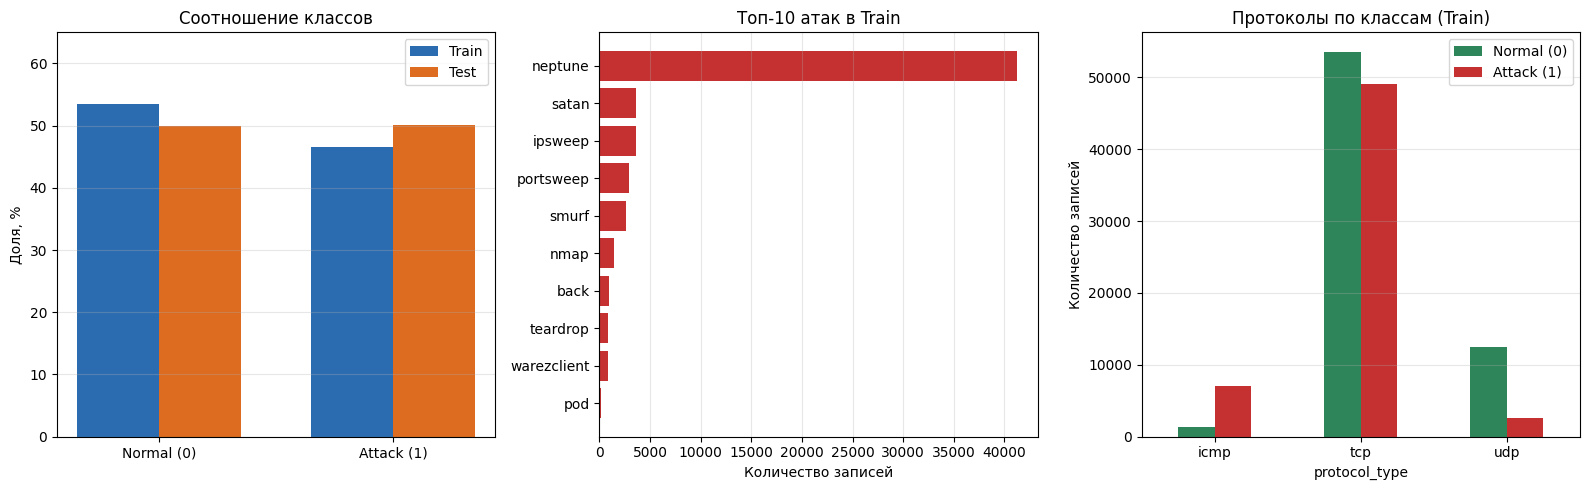

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Баланс классов Normal и Attack в процентах
positions = np.arange(2)
bar_width = 0.35
train_shares = (y_train_bin.value_counts(normalize=True).sort_index() * 100).values
test_shares = (y_test_bin.value_counts(normalize=True).sort_index() * 100).values

axes[0].bar(positions - bar_width / 2, train_shares, bar_width, label='Train', color='#2b6cb0')
axes[0].bar(positions + bar_width / 2, test_shares, bar_width, label='Test', color='#dd6b20')
axes[0].set_xticks(positions)
axes[0].set_xticklabels(['Normal (0)', 'Attack (1)'])
axes[0].set_ylabel('Доля, %')
axes[0].set_title('Соотношение классов')
axes[0].set_ylim(0, 65)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# 2. Десять самых частых атак в обучающей выборке
attacks_only = df_train[df_train['labels'] != 'normal']['labels']
top_attacks = attacks_only.value_counts().head(10).sort_values()

axes[1].barh(top_attacks.index, top_attacks.values, color='#c53030')
axes[1].set_title('Топ-10 атак в Train')
axes[1].set_xlabel('Количество записей')
axes[1].grid(axis='x', alpha=0.3)

# 3. Распределение протоколов для обычного трафика и атак
protocol_table = pd.crosstab(df_train['protocol_type'], y_train_bin)
protocol_table.columns = ['Normal (0)', 'Attack (1)']
protocol_table.plot(kind='bar', ax=axes[2], color=['#2f855a', '#c53030'], rot=0)
axes[2].set_title('Протоколы по классам (Train)')
axes[2].set_ylabel('Количество записей')
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
fig.savefig(processed_dir / 'eda_overview.png', dpi=150, bbox_inches='tight')
plt.show()

### Выводы по итогам анализа

1. В обоих файлах нет пропусков (`NaN` и скрытых пустых значений), а структура столбцов полностью совпадает (41 признак и целевой столбец `labels`).
2. Признак `num_outbound_cmds` всегда равен нулю в обеих выборках, поэтому его нужно исключать при подготовке данных.
3. Числовые признаки сильно отличаются по масштабу (например, флаги от 0 до 1 и `src_bytes` до 1.38 млрд), поэтому перед обучением моделей их нужно масштабировать.
4. Категориальные признаки (`protocol_type`, `service`, `flag`) нужно кодировать через `OneHotEncoder(handle_unknown='ignore')`, чтобы модели не падали на редких или новых категориях.
5. Бинарные классы (`Normal = 0`, `Attack = 1`) хорошо сбалансированы. В `kdd_test.csv` есть 14 видов атак, которых не было в `kdd_train.csv`, поэтому итоговое качество моделей обязательно нужно проверять на независимом тестовом наборе.
6. Все преобразования данных (кодирование категорий и масштабирование) на следующем этапе должны настраиваться только на обучающей выборке без утечки данных из теста.